In [1]:
import sys
from pathlib import Path

# Add project root to sys.path so we can import from utils
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

from utils.plotting import PALETTE, plot_cdf, plot_pdf, set_style

# Apply standard style across all plots
set_style()

# Continuous Uniform Distribution: The Baseline of Continuous Probability

## 1. Intuition & Motivation

Welcome to **continuous probability**! In discrete distributions (Binomial, Poisson), we could ask: *"What is the probability of getting exactly $k = 4$ events?"* and get a positive answer.

In continuous distributions, the variable can take **any real value** within an interval $[a, b]$—such as $4.1$, $4.1023$, or $4.1023847...$
Because there are infinitely many points:
- The probability of landing on any **exact specific point is zero**: $P(X = x) = 0$.
- Probability only exists over **intervals**: $P(x_1 \le X \le x_2)$.
- Instead of a mass function, we use a **Probability Density Function (PDF)** $f(x)$, where **probability is represented by the area under the curve**.

The **Continuous Uniform distribution** $\mathcal{U}(a, b)$ represents "complete lack of bias": every sub-interval of equal length has the exact same probability of containing the value.

### Real-World Examples:
- Arriving at a bus stop where a bus passes every 15 minutes: your wait time is $X \sim \mathcal{U}(0, 15)$.
- Round-off / quantization errors in digital signal processing and machine learning floats.
- **The Engine of Simulation**: Every computer-generated random number (NumPy, PyTorch, SciPy) starts as a $\mathcal{U}(0, 1)$ draw, which is then transformed into other distributions.

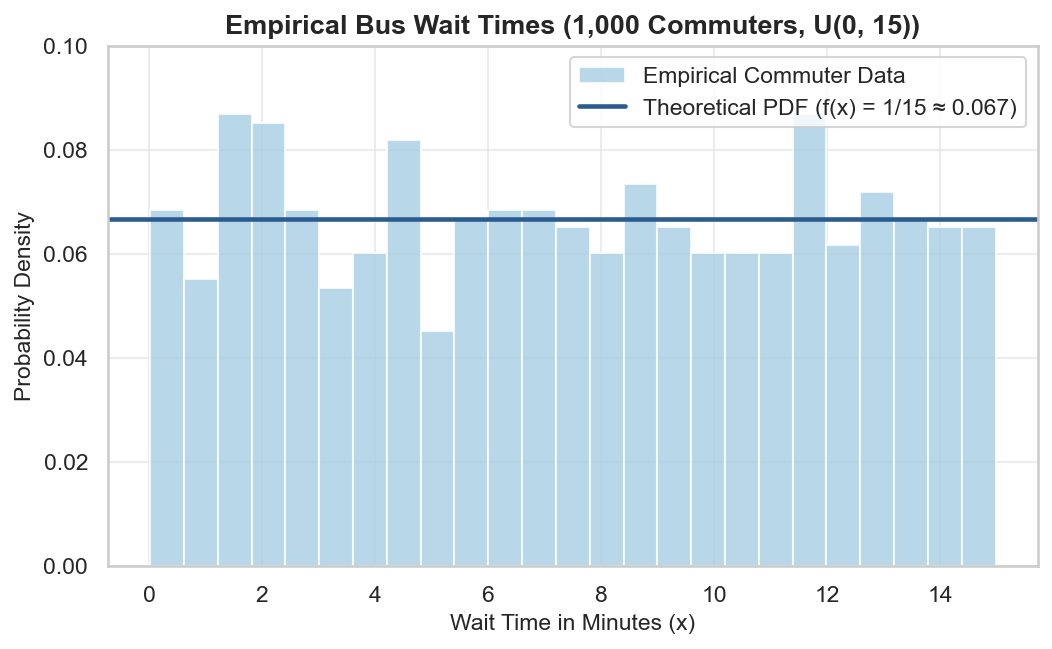

Sample Mean Wait Time: 7.46 mins (Theoretical: 7.50 mins)
Percentage of waits between 5 and 10 mins: 32.1%


In [2]:
# Parameters: Bus interval from 0 to 15 minutes
a_wait = 0.0
b_wait = 15.0
n_commuters = 1000

# Seed for reproducibility
rng = np.random.default_rng(seed=42)

# Generate continuous uniform draws
wait_times = rng.uniform(low=a_wait, high=b_wait, size=n_commuters)

# Plot empirical density histogram
plt.figure(figsize=(8, 4.5))
plt.hist(
    wait_times,
    bins=25,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label="Empirical Commuter Data",
)

# Overlay flat theoretical density line: 1 / (b - a) = 1 / 15
density_height = 1.0 / (b_wait - a_wait)
plt.axhline(
    density_height,
    color=PALETTE["primary"],
    linewidth=2.2,
    label=f"Theoretical PDF (f(x) = 1/15 ≈ {density_height:.3f})",
)

plt.title(
    f"Empirical Bus Wait Times (1,000 Commuters, U({a_wait:.0f}, {b_wait:.0f}))",
    weight="bold",
)
plt.xlabel("Wait Time in Minutes (x)")
plt.ylabel("Probability Density")
plt.ylim(0, 0.10)
plt.legend(frameon=True)
plt.show()

print(f"Sample Mean Wait Time: {np.mean(wait_times):.2f} mins (Theoretical: {(a_wait + b_wait)/2:.2f} mins)")
print(f"Percentage of waits between 5 and 10 mins: {np.mean((wait_times >= 5) & (wait_times <= 10)) * 100:.1f}%")

## 2. Mathematical Definition

A continuous random variable $X$ follows a Continuous Uniform distribution on interval $[a, b]$, written:
$$X \sim \mathcal{U}(a, b)$$

### Parameters & Support
- **$a \in \mathbb{R}$**: Lower bound (minimum).
- **$b \in \mathbb{R}$**: Upper bound (maximum), with $b > a$.
- **Support**: All real numbers in the closed interval $x \in [a, b]$.

### Probability Density Function (PDF)
Because every sub-interval of equal length has the same probability, the density is completely flat:
$$f(x) = \begin{cases} \frac{1}{b - a} & \text{for } a \le x \le b \\ 0 & \text{otherwise} \end{cases}$$
*(Notice the total area under the curve is $\text{width} \times \text{height} = (b - a) \times \frac{1}{b - a} = 1$.)*

### Cumulative Distribution Function (CDF)
The probability of landing at or below $x$ increases linearly from $0$ to $1$:
$$F(x) = P(X \le x) = \begin{cases} 0 & \text{if } x < a \\ \frac{x - a}{b - a} & \text{if } a \le x \le b \\ 1 & \text{if } x > b \end{cases}$$

### SciPy Parameterization Convention
In `scipy.stats.uniform(loc, scale)`:
- `loc = a` (the start point)
- `scale = b - a` (the width of the interval)
*(e.g., to model $\mathcal{U}(2, 10)$, use `loc=2, scale=8`).*

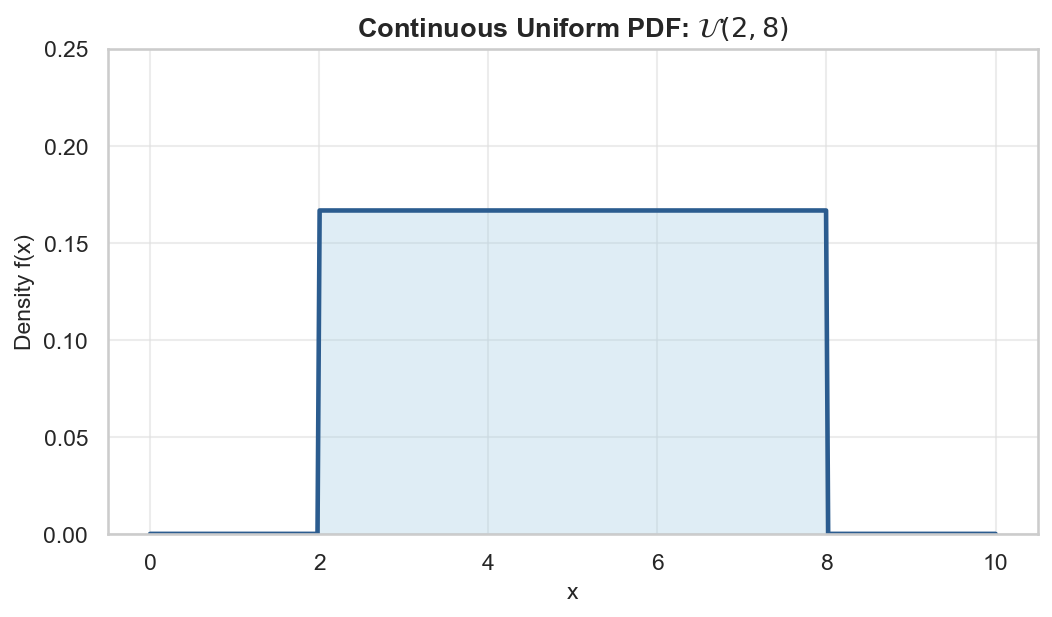

Constant Density Height: 1 / (b - a) = 1 / 6.0 = 0.1667


In [4]:
# Parameters: U(2, 8)
a = 2.0
b = 8.0
loc = a
scale = b - a  # width = 6.0

# Evaluation range spanning slightly outside [a, b]
x_vals = np.linspace(0.0, 10.0, 400)

# Evaluate exact theoretical PDF: f(x)
pdf_vals = stats.uniform.pdf(x_vals, loc=loc, scale=scale)

# Plot PDF using our continuous helper
fig, ax = plt.subplots(figsize=(8, 4.2))
plot_pdf(
    x_vals,
    pdf_vals,
    title = rf"Continuous Uniform PDF: $\mathcal{{U}}({a:.0f}, {b:.0f})$",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)
ax.set_ylim(0, 0.25)
plt.show()

print(f"Constant Density Height: 1 / (b - a) = 1 / {b - a} = {1 / scale:.4f}")

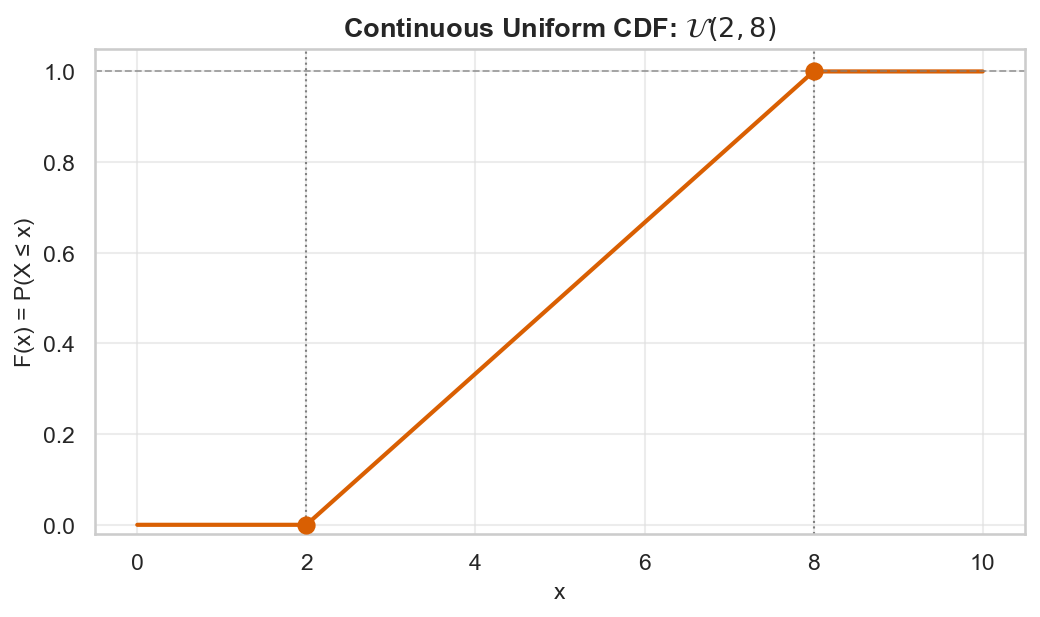

In [6]:
# Evaluate exact theoretical CDF: F(x) = P(X <= x)
cdf_vals = stats.uniform.cdf(x_vals, loc=loc, scale=scale)

fig, ax = plt.subplots(figsize=(8, 4.2))
plot_cdf(
    x_vals,
    cdf_vals,
    is_discrete=False,
    title = rf"Continuous Uniform CDF: $\mathcal{{U}}({a:.0f}, {b:.0f})$",
    xlabel="x",
    ylabel="F(x) = P(X ≤ x)",
    ax=ax,
)
# Highlight endpoints a and b
ax.scatter([a, b], [0, 1], color=PALETTE["secondary"], s=60, zorder=5)
ax.axvline(a, color="gray", linestyle=":", linewidth=1)
ax.axvline(b, color="gray", linestyle=":", linewidth=1)
plt.show()

## 3. Key Theoretical Properties

For $X \sim \mathcal{U}(a, b)$, its shape is completely defined by its boundaries:

### 1. Expected Value (Mean): $\mathbb{E}[X] = \mu$
$$\mu = \int_{a}^{b} x \cdot \frac{1}{b - a} \, dx = \frac{a + b}{2}$$
The mean is simply the geometric midpoint of the interval.

### 2. Variance & Standard Deviation: $\text{Var}(X) = \sigma^2$
Using $\text{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$:
$$\mathbb{E}[X^2] = \int_{a}^{b} x^2 \frac{1}{b - a} \, dx = \frac{b^3 - a^3}{3(b - a)} = \frac{a^2 + ab + b^2}{3}$$
$$\sigma^2 = \frac{a^2 + ab + b^2}{3} - \left(\frac{a + b}{2}\right)^2 = \frac{(b - a)^2}{12}$$
$$\sigma = \frac{b - a}{\sqrt{12}} = \frac{b - a}{2\sqrt{3}} \approx 0.2887 (b - a)$$

*(The factor of $12$ in the denominator is a celebrated constant in engineering, defining the noise power of round-off and digital quantization errors).*

### 3. Skewness: $\gamma_1$
$$\gamma_1 = 0$$
The distribution is **perfectly symmetric** about its midpoint.

### 4. Excess Kurtosis: $\gamma_2$
$$\gamma_2 = -\frac{6}{5} = -1.2$$
A negative excess kurtosis indicates that the distribution is **platykurtic** (flat-topped with no sharp central peak and truncated, non-existent tails).

In [8]:
# Parameters
a_test = 2.0
b_test = 8.0
loc_test = a_test
scale_test = b_test - a_test  # 6.0

# Analytical formulas
mu_formula = (a_test + b_test) / 2.0
var_formula = ((b_test - a_test) ** 2) / 12.0
std_formula = np.sqrt(var_formula)
skew_formula = 0.0
kurt_formula = -6.0 / 5.0  # -1.2

# SciPy calculation
mu_sp, var_sp, skew_sp, kurt_sp = stats.uniform.stats(
    loc=loc_test, scale=scale_test, moments="mvsk"
)

print("--- CONTINUOUS UNIFORM THEORETICAL MOMENTS ---")
print(f"Moment               | Analytical |    SciPy")
print("-" * 46)
print(f"Mean (μ)             | {mu_formula:10.4f} | {float(mu_sp):10.4f}")
print(f"Variance (σ²)        | {var_formula:10.4f} | {float(var_sp):10.4f}")
print(f"Std Deviation (σ)    | {std_formula:10.4f} | {np.sqrt(float(var_sp)):10.4f}")
print(f"Skewness (γ₁)        | {skew_formula:10.4f} | {float(skew_sp):10.4f}")
print(f"Excess Kurtosis (γ₂) | {kurt_formula:10.4f} | {float(kurt_sp):10.4f}")

--- CONTINUOUS UNIFORM THEORETICAL MOMENTS ---
Moment               | Analytical |    SciPy
----------------------------------------------
Mean (μ)             |     5.0000 |     5.0000
Variance (σ²)        |     3.0000 |     3.0000
Std Deviation (σ)    |     1.7321 |     1.7321
Skewness (γ₁)        |     0.0000 |     0.0000
Excess Kurtosis (γ₂) |    -1.2000 |    -1.2000


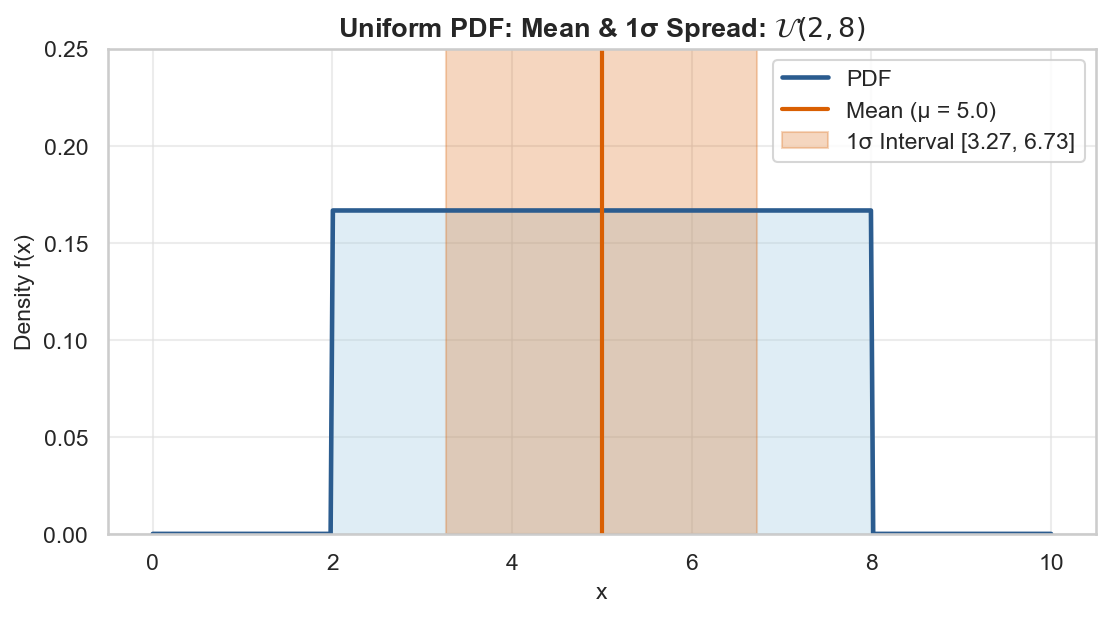

In [10]:
x_grid = np.linspace(0.0, 10.0, 400)
pdf_grid = stats.uniform.pdf(x_grid, loc=loc_test, scale=scale_test)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
plot_pdf(
    x_grid,
    pdf_grid,
    title=rf"Uniform PDF: Mean & 1σ Spread: $\mathcal{{U}}({a_test:.0f}, {b_test:.0f})$",
    xlabel="x",
    ylabel="Density f(x)",
    fill=True,
    ax=ax,
)

# Overlay Mean and 1-Sigma Band
ax.axvline(
    mu_formula,
    color=PALETTE["secondary"],
    linestyle="-",
    linewidth=2,
    label=f"Mean (μ = {mu_formula:.1f})",
)
ax.axvspan(
    mu_formula - std_formula,
    mu_formula + std_formula,
    color=PALETTE["secondary"],
    alpha=0.25,
    label=f"1σ Interval [{mu_formula - std_formula:.2f}, {mu_formula + std_formula:.2f}]",
)

ax.set_ylim(0, 0.25)
ax.legend(frameon=True)
plt.show()

## 4. Parameter Variation

The Uniform distribution is completely determined by its two boundaries, $a$ and $b$:

### 1. Shift (Location Transformation):
- Adding a constant $c$ shifts the distribution without changing its shape:
  $$X \sim \mathcal{U}(a, b) \implies X + c \sim \mathcal{U}(a + c, b + c)$$
- The variance $\sigma^2 = \frac{(b - a)^2}{12}$ and density height remain unchanged.

### 2. Stretch / Compression (Scale Transformation):
- The width $w = b - a$ dictates the density height:
  $$\text{Height} = f(x) = \frac{1}{w}$$
- **Narrow Interval (e.g., width = 2)**: Compressed width forces the density height to rise to $0.5$ to preserve total area = 1.
- **Wide Interval (e.g., width = 10)**: Expanded width dilutes the density down to $0.10$.
- In the CDF, the density height represents the **slope** of the ramp: $\frac{d}{dx}F(x) = f(x)$.

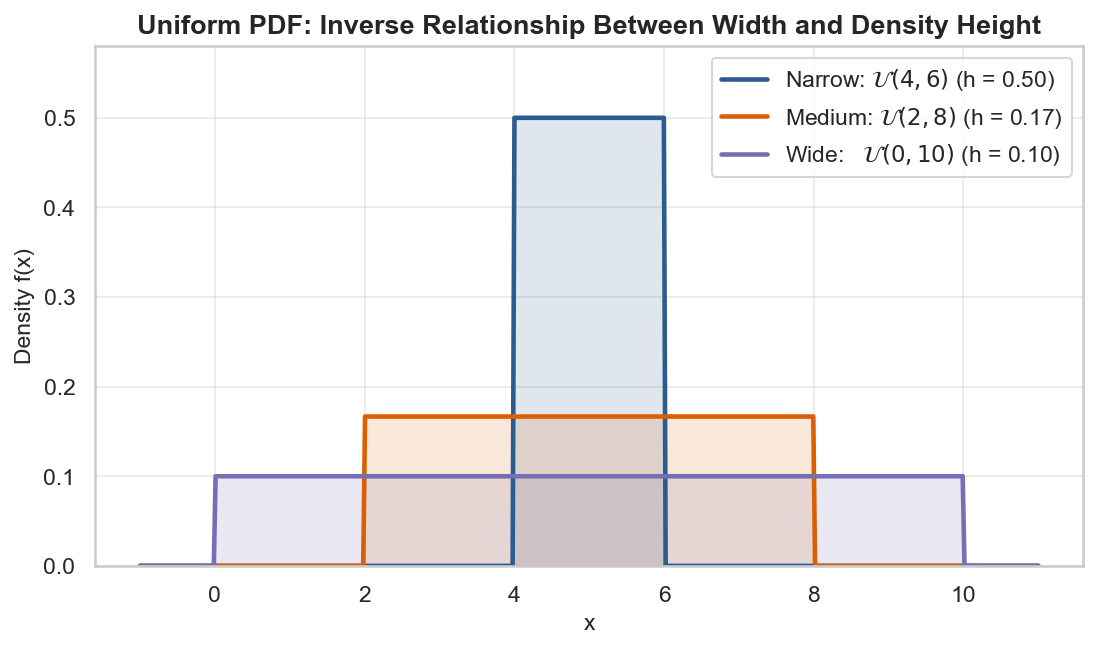

In [13]:
# Three distributions with identical center (mu = 5) but different widths
configs = [
    {"label": r"Narrow: $\mathcal{U}(4, 6)$",
     "a": 4.0, "b": 6.0, "color": PALETTE["primary"]},

    {"label": r"Medium: $\mathcal{U}(2, 8)$",
     "a": 2.0, "b": 8.0, "color": PALETTE["secondary"]},

    {"label": r"Wide:   $\mathcal{U}(0, 10)$",
     "a": 0.0, "b": 10.0, "color": PALETTE["accent"]},
]

x_axis = np.linspace(-1.0, 11.0, 500)
fig, ax = plt.subplots(figsize=(8.5, 4.5))

for cfg in configs:
    w = cfg["b"] - cfg["a"]
    pdf = stats.uniform.pdf(x_axis, loc=cfg["a"], scale=w)
    ax.plot(x_axis, pdf, label=rf"{cfg['label']} (h = {1/w:.2f})", color=cfg["color"], linewidth=2.2)
    ax.fill_between(x_axis, pdf, color=cfg["color"], alpha=0.15)

ax.set_title("Uniform PDF: Inverse Relationship Between Width and Density Height", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density f(x)")
ax.set_ylim(0, 0.58)
ax.legend(frameon=True)
plt.show()

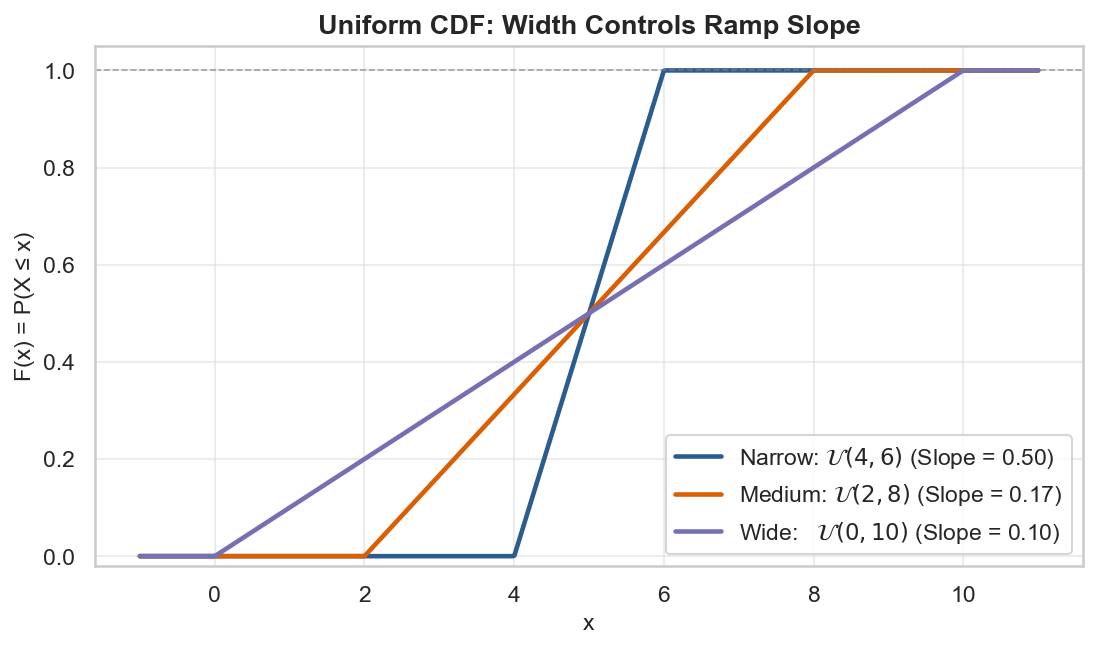

In [14]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))

for cfg in configs:
    w = cfg["b"] - cfg["a"]
    cdf = stats.uniform.cdf(x_axis, loc=cfg["a"], scale=w)
    ax.plot(
        x_axis,
        cdf,
        label=f"{cfg['label']} (Slope = {1/w:.2f})",
        color=cfg["color"],
        linewidth=2.2,
    )

ax.axhline(1.0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
ax.set_title("Uniform CDF: Width Controls Ramp Slope", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("F(x) = P(X ≤ x)")
ax.set_ylim(-0.02, 1.05)
ax.legend(frameon=True)
plt.show()

## 5. Simulation & Law of Large Numbers

When we draw $N$ independent continuous samples $X_1, X_2, \dots, X_N \sim \mathcal{U}(a, b)$:
- Each observation is a real number uniformly distributed between $a$ and $b$.
- By the **Law of Large Numbers (LLN)**, as sample size $N \to \infty$:
  $$\bar{X}_N = \frac{1}{N} \sum_{i=1}^{N} X_i \xrightarrow{P} \mu = \frac{a + b}{2}$$
  $$s^2_N = \frac{1}{N - 1} \sum_{i=1}^{N} (X_i - \bar{X}_N)^2 \xrightarrow{P} \sigma^2 = \frac{(b - a)^2}{12}$$

In a continuous histogram, data is partitioned into discrete bins. By the Glivenko-Cantelli Theorem, the binned empirical density converges uniformly to the flat theoretical box.

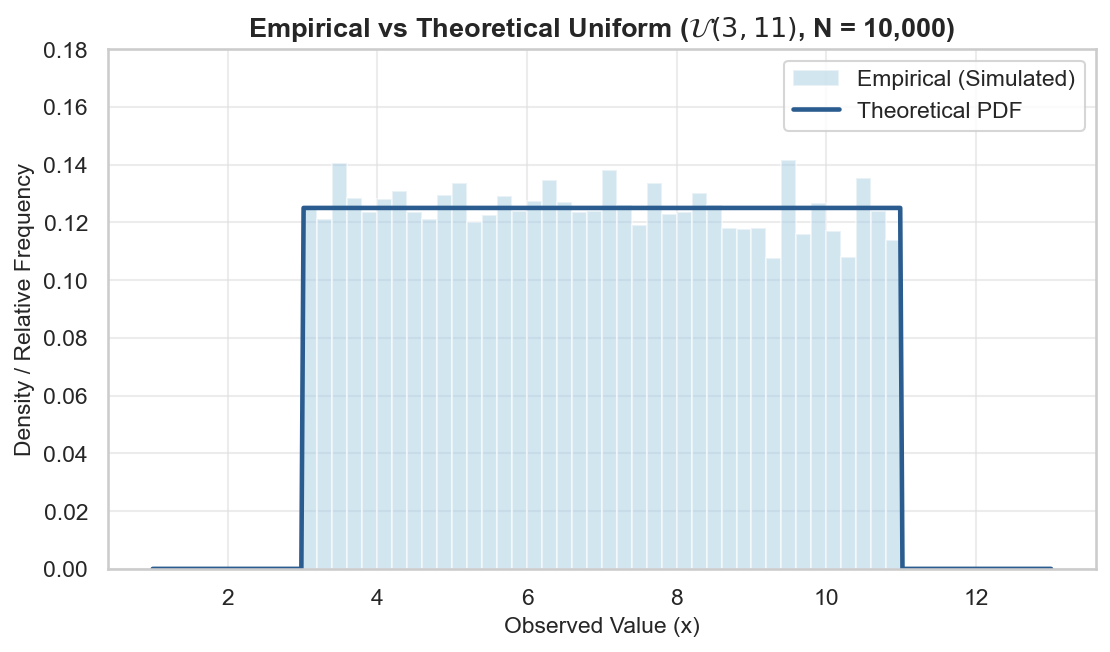

Theoretical Mean: 7.0000  |  Sample Mean: 6.9533
Theoretical Var:  5.3333  |  Sample Var:  5.2948


In [16]:
from utils.plotting import plot_sample_vs_theory

# Parameters: U(3, 11)
a_sim = 3.0
b_sim = 11.0
loc_sim = a_sim
scale_sim = b_sim - a_sim  # 8.0
sample_size = 10000

# Theoretical targets
mu_target = (a_sim + b_sim) / 2.0  # 7.0
var_target = ((b_sim - a_sim) ** 2) / 12.0  # 64 / 12 ≈ 5.333

# Generate random continuous variates using SciPy
samples_uni = stats.uniform.rvs(
    loc=loc_sim, scale=scale_sim, size=sample_size, random_state=42
)

# Theoretical coordinates
x_theory = np.linspace(1.0, 13.0, 400)
pdf_theory = stats.uniform.pdf(x_theory, loc=loc_sim, scale=scale_sim)

# Plot empirical histogram vs continuous PDF
fig, ax = plt.subplots(figsize=(8.5, 4.5))
plot_sample_vs_theory(
    samples=samples_uni,
    x_theory=x_theory,
    y_theory=pdf_theory,
    is_discrete=False,
    title=rf"Empirical vs Theoretical Uniform ($\mathcal{{U}}({a_sim:.0f}, {b_sim:.0f})$, N = {sample_size:,})",
    xlabel="Observed Value (x)",
    ax=ax,
)
ax.set_ylim(0, 0.18)
plt.show()

# Verification metrics
print(f"Theoretical Mean: {mu_target:.4f}  |  Sample Mean: {np.mean(samples_uni):.4f}")
print(f"Theoretical Var:  {var_target:.4f}  |  Sample Var:  {np.var(samples_uni, ddof=1):.4f}")

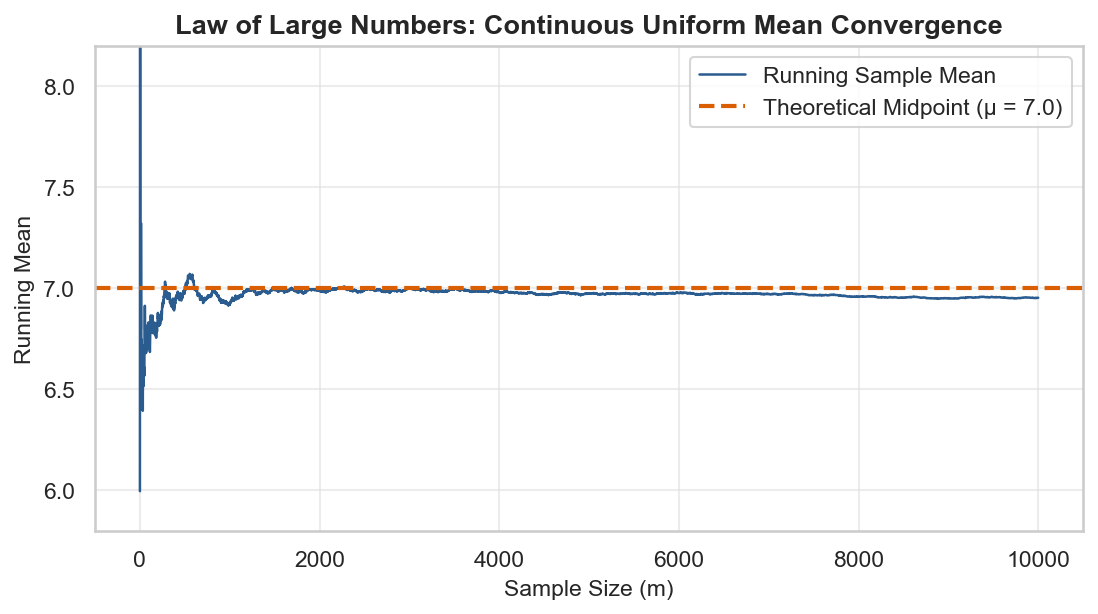

In [17]:
# Compute sequential running mean
m_indices = np.arange(1, sample_size + 1)
running_mean = np.cumsum(samples_uni) / m_indices

plt.figure(figsize=(8.5, 4.2))
plt.plot(
    m_indices,
    running_mean,
    color=PALETTE["primary"],
    linewidth=1.2,
    label="Running Sample Mean",
)
plt.axhline(
    mu_target,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Midpoint (μ = {mu_target:.1f})",
)

plt.title("Law of Large Numbers: Continuous Uniform Mean Convergence")
plt.xlabel("Sample Size (m)")
plt.ylabel("Running Mean")
plt.ylim(mu_target - 1.2, mu_target + 1.2)
plt.legend(frameon=True)
plt.show()

## 6. Applied Real-World Use Case: Digital Quantization Noise (Bennett's Model)

### Scenario
When deploying machine learning models to mobile devices (e.g., INT8 quantization) or recording digital audio (Analog-to-Digital conversion), continuous real-valued numbers must be rounded to the nearest discrete step:
$$\Delta = \text{quantization step size}$$

### The Uniform Noise Model
If the signal varies smoothly across many quantization levels, the rounding error (residual) $\epsilon = x - x_{\text{quantized}}$ is uniformly distributed across the interval of half a step in either direction:
$$\epsilon \sim \mathcal{U}\left(-\frac{\Delta}{2}, \frac{\Delta}{2}\right)$$

### Key Engineering Insights:
1. **Unbiased Mean**: $\mathbb{E}[\epsilon] = \frac{-\Delta/2 + \Delta/2}{2} = 0$ (no systematic drift).
2. **Noise Power (Variance)**:
   $$\sigma_{\epsilon}^2 = \frac{\big(\frac{\Delta}{2} - (-\frac{\Delta}{2})\big)^2}{12} = \frac{\Delta^2}{12}$$
   *(This is the celebrated **Bennett's formula** used across audio, telecommunications, and deep learning hardware).*
3. **Signal-to-Quantization-Noise Ratio (SQNR)**:
   Adding bits of precision reduces $\Delta$, dramatically suppressing the noise floor.

In [18]:
# Signal parameters
n_bits = 8  # 8-bit quantization (256 discrete levels)
v_min, v_max = -1.0, 1.0  # Dynamic range = 2.0 V
n_levels = 2**n_bits
delta = (v_max - v_min) / n_levels  # Step size Delta ≈ 0.0078125 V

# Generate continuous signal: smooth multi-tone waveform with 10,000 points
t = np.linspace(0, 1, 10000)
signal_continuous = 0.8 * np.sin(2 * np.pi * 5 * t) + 0.15 * np.cos(
    2 * np.pi * 12 * t
)

# Quantize signal to nearest discrete step
signal_quantized = np.round((signal_continuous - v_min) / delta) * delta + v_min

# Compute error residuals: epsilon = continuous - quantized
quant_error = signal_continuous - signal_quantized

# Theoretical metrics
theoretical_noise_var = (delta**2) / 12.0
empirical_noise_var = np.var(quant_error, ddof=1)

print("--- 8-BIT QUANTIZATION NOISE ANALYSIS ---")
print(f"Number of Bits:          {n_bits} ({n_levels} discrete levels)")
print(f"Step Size (Δ):           {delta:.6f} V")
print(f"Theoretical Noise Range: [{-delta/2:.6f}, {delta/2:.6f}] V\n")
print(f"Theoretical Variance (Δ²/12): {theoretical_noise_var:.4e} V²")
print(f"Empirical Error Variance:     {empirical_noise_var:.4e} V²")
print(f"Mean Rounding Error:          {np.mean(quant_error):.2e} V (≈ 0)")

--- 8-BIT QUANTIZATION NOISE ANALYSIS ---
Number of Bits:          8 (256 discrete levels)
Step Size (Δ):           0.007812 V
Theoretical Noise Range: [-0.003906, 0.003906] V

Theoretical Variance (Δ²/12): 5.0863e-06 V²
Empirical Error Variance:     5.1230e-06 V²
Mean Rounding Error:          -4.98e-05 V (≈ 0)


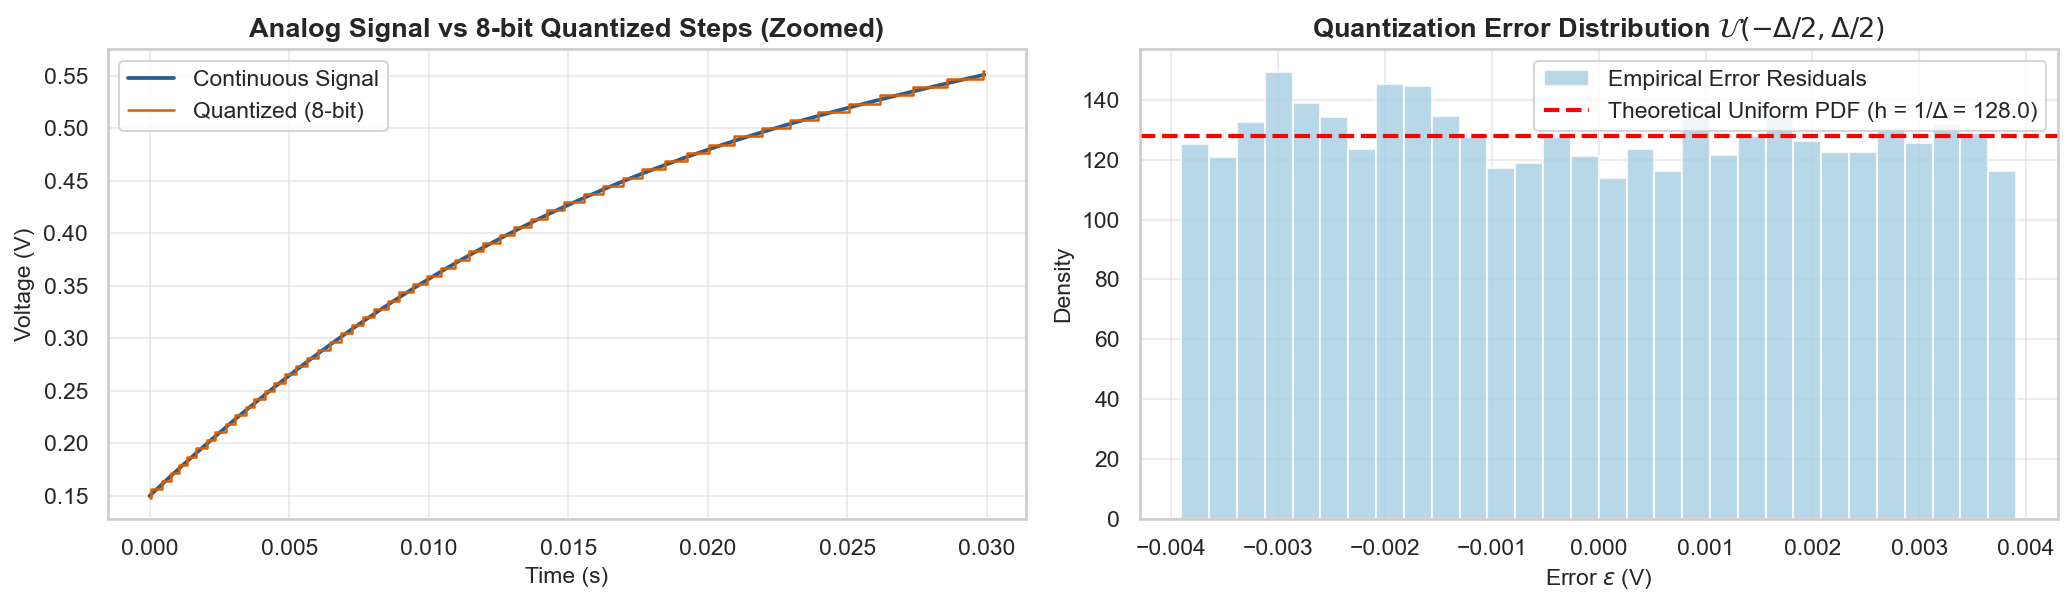

In [21]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))

# Subplot 1: Zoomed view of continuous vs quantized waveform
zoom_idx = slice(0, 300)
ax1.plot(
    t[zoom_idx],
    signal_continuous[zoom_idx],
    color=PALETTE["primary"],
    linewidth=1.8,
    label="Continuous Signal",
)
ax1.step(
    t[zoom_idx],
    signal_quantized[zoom_idx],
    where="mid",
    color=PALETTE["secondary"],
    linewidth=1.2,
    label="Quantized (8-bit)",
)
ax1.set_title("Analog Signal vs 8-bit Quantized Steps (Zoomed)", weight="bold")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Voltage (V)")
ax1.legend(frameon=True)

# Subplot 2: Histogram of quantization error residuals
ax2.hist(
    quant_error,
    bins=30,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label="Empirical Error Residuals",
)
ax2.axhline(
    1.0 / delta,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Theoretical Uniform PDF (h = 1/Δ = {1/delta:.1f})",
)
ax2.set_title(r"Quantization Error Distribution $\mathcal{U}(-\Delta/2, \Delta/2)$", weight="bold")
ax2.set_xlabel(r"Error $\epsilon$ (V)")
ax2.set_ylabel("Density")
ax2.legend(frameon=True)

plt.tight_layout()
plt.show()

## 7. Parameter Estimation (MLE & The German Tank Problem)

Suppose we observe $N$ independent continuous samples $x_1, x_2, \dots, x_N$ and wish to estimate the unknown boundaries $[a, b]$.

### Why Calculus Fails:
The likelihood function is:
$$L(a, b) = \prod_{i=1}^{N} \frac{1}{b - a} \cdot \mathbb{I}(a \le x_i \le b) = \frac{1}{(b - a)^N}$$
*provided* $a \le \min(x)$ and $b \ge \max(x)$, and $0$ otherwise.

Notice that $\frac{1}{(b - a)^N}$ has no interior stationary point where the derivative equals zero!
Instead, to maximize $L(a, b)$, we must make the denominator $(b - a)$ **as small as possible** while still containing all data points.

Therefore, the maximum occurs at the exact boundary of the data:
$$\hat{a}_{\text{MLE}} = \min(x_1, \dots, x_N) = x_{(1)}$$
$$\hat{b}_{\text{MLE}} = \max(x_1, \dots, x_N) = x_{(N)}$$

### The Bias & The German Tank Problem
The sample maximum $x_{(N)}$ is **systematically biased downward** ($\mathbb{E}[x_{(N)}] < b$) because you can never observe a value greater than the true maximum!
For a uniform distribution on $[0, b]$, probability theory proves that the sample maximum captures on average $\frac{N}{N+1}$ of the range:
$$\mathbb{E}[x_{(N)}] = \frac{N}{N + 1} b$$

To correct for this bias, the Minimum-Variance Unbiased Estimator (MVUE)—famously used by Allied statisticians in WWII to estimate German tank production from captured gearbox serial numbers—is:
$$\hat{b}_{\text{unbiased}} = x_{(N)} \cdot \frac{N + 1}{N}$$

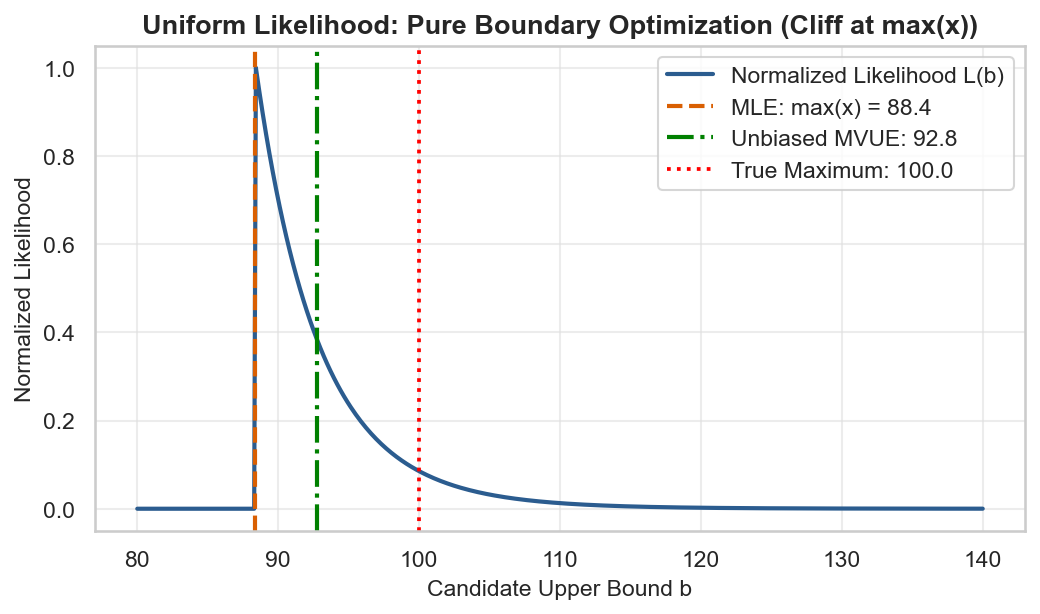

Sample Maximum (MLE):       88.36 (Underestimates true 100)
German Tank Unbiased MVUE:  92.78 (Near true 100!)
Method of Moments (2 * x̄):  84.24


In [22]:
# True boundary parameters: U(0, 100)
a_true = 0.0
b_true = 100.0
N_obs = 20

# Generate synthetic observations
data_uniform = stats.uniform.rvs(
    loc=a_true, scale=b_true, size=N_obs, random_state=105
)

# 1. Pure MLE: sample maximum
b_mle = np.max(data_uniform)

# 2. Bias-corrected German Tank MVUE: max * (N + 1) / N
b_unbiased = b_mle * (N_obs + 1) / N_obs

# 3. Method of Moments: 2 * sample_mean (for a = 0)
b_mom = 2.0 * np.mean(data_uniform)

# Evaluate Likelihood curve as a function of candidate upper bound b
b_grid = np.linspace(80.0, 140.0, 500)
# Likelihood is (1/b)^N if b >= max(data), else 0
likelihood_curve = np.where(b_grid >= b_mle, (1.0 / b_grid) ** N_obs, 0.0)

# Normalize for plotting
likelihood_norm = likelihood_curve / np.max(likelihood_curve)

plt.figure(figsize=(8, 4.2))
plt.plot(
    b_grid,
    likelihood_norm,
    color=PALETTE["primary"],
    linewidth=2,
    label="Normalized Likelihood L(b)",
)
plt.axvline(
    b_mle,
    color=PALETTE["secondary"],
    linestyle="--",
    linewidth=2,
    label=f"MLE: max(x) = {b_mle:.1f}",
)
plt.axvline(
    b_unbiased,
    color="green",
    linestyle="-.",
    linewidth=2,
    label=f"Unbiased MVUE: {b_unbiased:.1f}",
)
plt.axvline(
    b_true,
    color="red",
    linestyle=":",
    linewidth=1.8,
    label=f"True Maximum: {b_true:.1f}",
)

plt.title("Uniform Likelihood: Pure Boundary Optimization (Cliff at max(x))", weight="bold")
plt.xlabel("Candidate Upper Bound b")
plt.ylabel("Normalized Likelihood")
plt.legend(frameon=True)
plt.show()

print(f"Sample Maximum (MLE):       {b_mle:.2f} (Underestimates true {b_true:.0f})")
print(f"German Tank Unbiased MVUE:  {b_unbiased:.2f} (Near true {b_true:.0f}!)")
print(f"Method of Moments (2 * x̄):  {b_mom:.2f}")

In [23]:
n_experiments = 2000
mle_estimates = []
mvue_estimates = []

for _ in range(n_experiments):
    batch = rng.uniform(0, b_true, size=N_obs)
    m = np.max(batch)
    mle_estimates.append(m)
    mvue_estimates.append(m * (N_obs + 1) / N_obs)

print("--- 2,000 MONTE CARLO EXPERIMENTS OF ESTIMATOR BIAS ---")
print(f"True Upper Bound:                 {b_true:.2f}")
print(f"Average MLE Estimate (max):       {np.mean(mle_estimates):.2f} (Biased downward by ~{b_true - np.mean(mle_estimates):.2f})")
print(f"Theoretical E[max] = N/(N+1)*b:   {N_obs / (N_obs + 1) * b_true:.2f}")
print(f"Average German Tank MVUE:         {np.mean(mvue_estimates):.2f} (Perfectly Unbiased!)")

--- 2,000 MONTE CARLO EXPERIMENTS OF ESTIMATOR BIAS ---
True Upper Bound:                 100.00
Average MLE Estimate (max):       95.16 (Biased downward by ~4.84)
Theoretical E[max] = N/(N+1)*b:   95.24
Average German Tank MVUE:         99.92 (Perfectly Unbiased!)


## 8. Related Distributions & Summary

The Continuous Uniform distribution $\mathcal{U}(0, 1)$ is the foundational seed of computational statistics:

### 1. Inverse Transform Sampling (Universal Generator)
Let $U \sim \mathcal{U}(0, 1)$. For **any** continuous cumulative distribution function $F(x)$ with an inverse quantile function $F^{-1}(u)$:
$$X = F^{-1}(U) \sim F$$
*Every pseudo-random number generator in software (NumPy, SciPy, PyTorch) starts with a uniform random number and applies inverse CDFs to generate Exponential, Weibull, Cauchy, and Logistic variates!*

### 2. Beta Distribution ($\text{Beta}(1, 1)$):
- The **Beta distribution** on $[0, 1]$ with shape parameters $\alpha = 1, \beta = 1$ is mathematically identical to the standard Uniform distribution:
  $$\text{Beta}(1, 1) \equiv \mathcal{U}(0, 1)$$

### 3. Irwin-Hall Distribution & Early Normal Generators:
- The sum of $n$ independent $\mathcal{U}(0, 1)$ variables follows an **Irwin-Hall distribution**.
- For $n = 12$, the sum has mean $\mu = 6$ and variance $\sigma^2 = 12 \times \frac{1}{12} = 1$. Early computers generated standard normal numbers by simply taking:
  $$Z = \sum_{i=1}^{12} U_i - 6 \approx \mathcal{N}(0, 1)$$

### 4. Hypothesis Testing & p-values:
- Under the null hypothesis $H_0$, a correctly calibrated statistical test produces **p-values that are uniformly distributed on $[0, 1]$**:
  $$p\text{-value} \sim \mathcal{U}(0, 1)$$

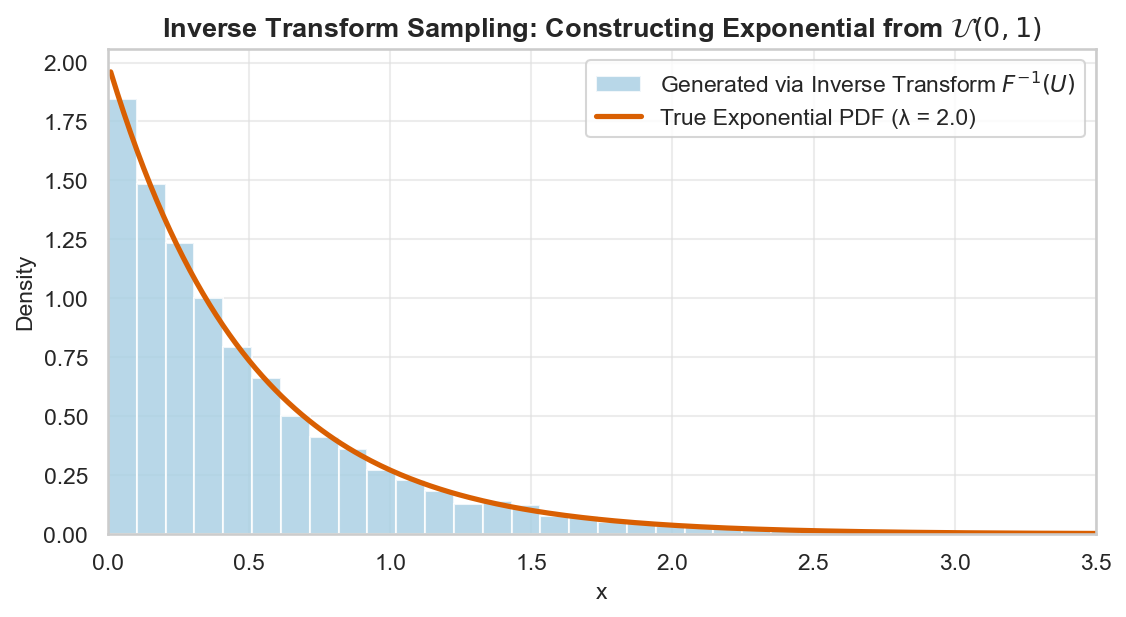

Sample Mean of Generated Exp: 0.4887 (Theoretical: 0.5000)
Sample Var of Generated Exp:  0.2374 (Theoretical: 0.2500)


In [25]:
# Target: Exponential distribution with rate lambda = 2.0 (mean = 0.5)
lam_target = 2.0
N_sim = 10000

# 1. Generate standard uniform draws: U ~ U(0, 1)
u_draws = stats.uniform.rvs(loc=0.0, scale=1.0, size=N_sim, random_state=42)

# 2. Apply Analytical Inverse CDF of Exponential: F^-1(u) = -ln(1 - u) / lambda
generated_exponential = -np.log(1.0 - u_draws) / lam_target

# 3. Compare empirical histogram against true theoretical Exponential PDF
x_exp_eval = np.linspace(0.01, 3.5, 300)
pdf_exp_true = stats.expon.pdf(x_exp_eval, scale=1.0 / lam_target)

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.hist(
    generated_exponential,
    bins=40,
    density=True,
    color=PALETTE["fill"],
    edgecolor="white",
    alpha=0.8,
    label="Generated via Inverse Transform $F^{-1}(U)$",
)
ax.plot(
    x_exp_eval,
    pdf_exp_true,
    color=PALETTE["secondary"],
    linewidth=2.5,
    label=f"True Exponential PDF (λ = {lam_target})",
)

ax.set_title(r"Inverse Transform Sampling: Constructing Exponential from $\mathcal{U}(0, 1)$", weight="bold")
ax.set_xlabel("x")
ax.set_ylabel("Density")
ax.set_xlim(0, 3.5)
ax.legend(frameon=True)
plt.show()

print(f"Sample Mean of Generated Exp: {np.mean(generated_exponential):.4f} (Theoretical: {1/lam_target:.4f})")
print(f"Sample Var of Generated Exp:  {np.var(generated_exponential, ddof=1):.4f} (Theoretical: {1/(lam_target**2):.4f})")

### Summary Card: Continuous Uniform Distribution

| Property | Formulation |
| :--- | :--- |
| **Notation** | $X \sim \mathcal{U}(a, b)$ |
| **Parameters** | $a \in \mathbb{R}$ (minimum), $b \in \mathbb{R}$ (maximum), with $b > a$ |
| **Support** | $x \in [a, b]$ |
| **PDF** | $f(x) = \frac{1}{b - a}$ for $a \le x \le b$ (0 otherwise) |
| **CDF** | $F(x) = \frac{x - a}{b - a}$ for $a \le x \le b$ |
| **Mean ($\mu$)** | $\frac{a + b}{2}$ (Midpoint) |
| **Variance ($\sigma^2$)** | $\frac{(b - a)^2}{12}$ |
| **Standard Deviation ($\sigma$)** | $\frac{b - a}{\sqrt{12}} = \frac{b - a}{2\sqrt{3}}$ |
| **Skewness ($\gamma_1$)** | $0$ (Symmetric) |
| **Excess Kurtosis ($\gamma_2$)** | $-\frac{6}{5} = -1.2$ (Platykurtic / flat) |
| **MLE Estimators** | $\hat{a} = \min(x)$, $\hat{b} = \max(x)$ (Order statistics, boundary solution) |
| **Unbiased MVUE** | $\hat{b}_{\text{unbiased}} = \max(x) \cdot \frac{N + 1}{N}$ (German Tank Problem) |
| **Universal Generator** | Inverse Transform Sampling: $X = F^{-1}(U)$ |
| **Key Use Cases** | Random number generation, digital quantization / rounding noise, Monte Carlo integration |